# L2.3 · Choose and check an income model

**PowerPoint slides** 22–24  
**Course data** customers_raw.csv

### The problem

Can two recorded clues, account balance and time as a customer, help guess income when it is missing?

### What this demo shows

Start with a middle-income guess, then fit a line with a setting called alpha that controls how much its weights can grow. Compare a few settings and check the chosen one on separate customers.

### Why we’re doing it

People whose income is recorded can differ from people who need a guess. We need to check the size of the misses and see which customers the check represents.

**If this is your first ML activity**, open [00 · Your first ML workflow](00_Start_Here_Your_First_ML_Workflow.ipynb) first. For the simpler examples of model types and repeated checking, see [01 · Regression and classification](01_Regression_and_Classification.ipynb) and [03 · K-fold cross-validation](03_K_Fold_Cross_Validation.ipynb).

Here, read the plain-English explanation before each cell. Run **Setup**, then work down the page with **Shift + Enter**.

## Setup · Load the data

Read a small customer slice, remove repeated IDs, clean the salary field and keep usable labels. This file is a customer snapshot, so this example splits customers into three groups. The two model inputs are balance and tenure. The first few lines locate the course data folder. You can
run the whole cell as written.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

working_folder = Path.cwd()
data_folder = next(
    (folder / 'data' for folder in (working_folder, *working_folder.parents)
     if (folder / 'data' / 'property_valuations.csv').is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError('Open the extracted course folder in Jupyter or VS Code.')

columns = ["customer_id", "monthly_salary_aed", "salary_transfer", "employment_type",
           "avg_balance_aed", "tenure_months"]
customers = pd.read_csv(data_folder / "customers_raw.csv", usecols=columns, nrows=5000)
customers = customers.drop_duplicates("customer_id").copy()
salary_text = customers["monthly_salary_aed"].astype("string")
salary_text = salary_text.str.replace("AED", "", regex=False).str.replace(",", "", regex=False).str.strip()
customers["salary"] = pd.to_numeric(salary_text, errors="coerce")
features = ["avg_balance_aed", "tenure_months"]
known = customers[(customers["salary_transfer"] == 1) & (customers["salary"] > 0)]
known = known.dropna(subset=features)
known = known[(known["avg_balance_aed"] >= 0) & (known["tenure_months"] >= 0)]
train, remaining = train_test_split(known, test_size=0.4, random_state=42)
validation, test = train_test_split(remaining, test_size=0.5, random_state=42)
print("Training:", len(train), "· validation:", len(validation), "· test:", len(test))

Training: 1744 · validation: 582 · test: 582


## 1 · See who has a usable label

**What we’re doing.** Compare how many people are self-employed in the group with usable salaries and among people without a salary transfer.

**Why we’re doing it.** A group with few recorded answers gives the model less to learn from. It also gives us less evidence about how well our guesses will work for that group.

**What to look for.** The proportions differ in this slice. Employment type is used to inspect representation.

In [2]:
to_score = customers[customers["salary_transfer"] == 0]
print(f"Usable salary rows: {len(known):,}")
print(f"No salary transfer: {len(to_score):,}")
print(f"Self-employed among labelled: {known['employment_type'].eq('Self_Employed').mean():.1%}")
print(f"Self-employed without transfer: {to_score['employment_type'].eq('Self_Employed').mean():.1%}")

Usable salary rows: 2,908
No salary transfer: 1,940
Self-employed among labelled: 3.2%
Self-employed without transfer: 26.5%


### See who is represented in each group

Compare the two bars. The group that needs an income estimate includes a larger share of self-employed customers.

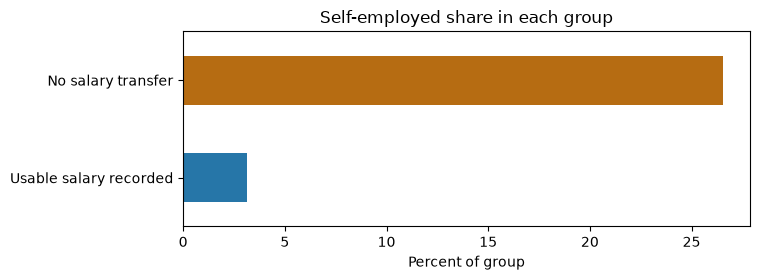

In [3]:
import matplotlib.pyplot as plt

shares = pd.Series({
    "Usable salary recorded": known["employment_type"].eq("Self_Employed").mean() * 100,
    "No salary transfer": to_score["employment_type"].eq("Self_Employed").mean() * 100,
})
ax = shares.plot.barh(figsize=(7.7, 2.9), color=["#2676a8", "#b66c12"])
ax.set(title="Self-employed share in each group", xlabel="Percent of group", ylabel="")
plt.tight_layout()
plt.show()

## 2 · Set a baseline

**What we’re doing.** Use the middle training salary as the same guess for every person in validation.

**Why we’re doing it.** This gives us a simple number to beat before we try fitting a line.

**What to look for.** Read the second number as the average size of a miss in AED.

In [4]:
salary_guess = train["salary"].median()
guess_error = (validation["salary"] - salary_guess).abs().mean()
print(f"Median guess: AED {salary_guess:,.0f}")
print(f"Validation MAE: AED {guess_error:,.0f}")

Median guess: AED 12,715
Validation MAE: AED 8,034


## 3 · Try three settings

**What we’re doing.** Try three strength settings for a Ridge line. Put both inputs on comparable scales using training rows.

**Why we’re doing it.** A line can lean too heavily on one clue. A stronger setting can reduce those weights. We compare settings on validation rows so the choice has a fair check.

**What to look for.** Choose the setting with the smallest validation error and compare it with the median baseline.

In [5]:
candidates = {}
scores = {}
for alpha in [0.1, 10, 1000]:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model.fit(train[features], train["salary"])
    estimate = model.predict(validation[features])
    candidates[alpha] = model
    scores[alpha] = (validation["salary"] - estimate).abs().mean()
display(pd.Series(scores, name="Validation MAE (AED)").round(0))

0.1       7578.0
10.0      7580.0
1000.0    7728.0
Name: Validation MAE (AED), dtype: float64

## 4 · Read four search strategies

**What we’re doing.** Imagine testing Ridge with three strengths. Read
which candidate gets a turn under each strategy.

**Why we’re doing it.** Trying every setting can take too long. The search method helps decide which guesses to try first.

| Strategy | Example with candidate values |
|---|---|
| Grid | Try every listed candidate, here 0.1, 10 and 1,000. |
| Random | Draw a limited number of candidates from the search space. With a budget of two draws we might try 0.1 and 1,000. |
| Successive halving | Try many candidates on a small data or compute budget. Continue with the strongest few using more resources. |
| Bayesian | Use the scores already measured to decide which new value looks most informative or promising. |

**Look for.** The grid in step 3 shows the outcome of three choices. The
other rows describe how to choose trials when the candidate list is large.

## 5 · Put tuning inside another check

**What we’re doing.** Try settings on inner groups of rows, then check the selected setting on an outer group that stayed aside.

**Why we’re doing it.** The best setting can look unusually good on the group that helped choose it. The outer group gives that choice a fresh check, and we repeat it for several groups.

**What to look for.** The evaluation yields three errors. The minus sign converts scikit-learn’s score back to positive MAE.

In [6]:
ridge = make_pipeline(StandardScaler(), Ridge())
inner_search = GridSearchCV(ridge, {"ridge__alpha": [0.1, 10, 1000]},
                            cv=2, scoring="neg_mean_absolute_error")
outer = KFold(n_splits=3, shuffle=True, random_state=42)
fold_scores = cross_val_score(inner_search, train[features], train["salary"],
                              cv=outer, scoring="neg_mean_absolute_error")
print("Outer MAEs in AED:", (-fold_scores).round(0))

Outer MAEs in AED: [7199. 7525. 7485.]


## 6 · Fix the setting and check later-use errors

**What we’re doing.** Use the chosen setting on the reserved test customers. Compare their misses with the middle-value guess and look at the results by employment group.

**Why we’re doing it.** A model’s overall score can hide a group where the guesses are less accurate. Counts tell us how many people support each score.

**What to look for.** Read the test count next to each group’s average. A small count makes the group average harder to generalise.

In [7]:
chosen_alpha = min(scores, key=scores.get)
chosen_model = candidates[chosen_alpha]
test_estimate = chosen_model.predict(test[features])
differences = test["salary"] - test_estimate
print(f"Chosen alpha: {chosen_alpha} · test MAE: AED {differences.abs().mean():,.0f}")
print(f"Median test MAE: AED {(test['salary'] - salary_guess).abs().mean():,.0f}")
group_check = test.assign(absolute_error=differences.abs())
display(group_check.groupby("employment_type")["absolute_error"].agg(["count", "mean"]).round(0))

Chosen alpha: 0.1 · test MAE: AED 7,888
Median test MAE: AED 8,770


,count,mean
employment_type,,
Government,113,9956.0
Private,447,7369.0
Retired,3,9828.0
Self_Employed,19,7503.0


## 7 · Make a cautious estimate

**What we’re doing.** Use the larger downward misses from validation to lower the income guesses, then check how often actual test salaries are above the lower guess.

**Why we’re doing it.** When a guess that is too high is costly, a lower guess may be useful. The validation results help us pick the adjustment before the final check.

**What to look for.** The result is measured on customers with usable observed salaries. The same coverage may differ for a group with few or no labels.

In [8]:
validation_estimate = chosen_model.predict(validation[features])
validation_residual = validation["salary"] - validation_estimate
shift = validation_residual.quantile(0.20)
cautious = (test_estimate + shift).clip(0, None)
print(f"Shift from validation: AED {shift:,.0f}")
print(f"Test salaries at or above this estimate: {test['salary'].ge(cautious).mean():.1%}")

Shift from validation: AED -7,156
Test salaries at or above this estimate: 81.3%


**Recall from D2.1.** A learning rate changes the size of an update, a
batch is the set of rows used in an update, and an epoch is one pass
through the training data. This short demo compares Ridge settings using
scikit-learn’s fitting method.

### Your turn

Point to the cohort that chooses alpha, the cohort that chooses the
cautious shift, and the cohort that provides the final check. Explain why
a customer with no observed income cannot supply an error.